# Regression Modelling and Energy-Loss Estimation

This notebook compares Random Forest and XGBoost regression models. The selected model learns expected turbine power during normal operation and estimates energy loss across all recorded intervals.

In [1]:
import pandas as pd
import time
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_validate
from xgboost import XGBRegressor

features = pd.read_csv("../out/02_clustering/wind_features_clustered.csv")

print(features.shape)
print(features["cluster_state"].value_counts())

(50530, 23)
cluster_state
0                        40476
below_operating_range     9895
dbscan_noise                99
1                           42
2                           10
3                            8
Name: count, dtype: int64


## 1. Select Normal-Operation Records

DBSCAN cluster `0` was selected as the normal-operation cluster because it contained the majority of operating-region records and had the highest median power ratio. Only these records are used to train the regression models so that abnormal observations do not define the healthy power curve.

In [2]:
normal_cluster = 0

normal_data = features[
    features["cluster"] == normal_cluster
].copy()

print("Normal data shape:", normal_data.shape)

Normal data shape: (40476, 23)


## 2. Define Predictors and Target

The predictors are `wind_speed`, `wd_sin`, and `wd_cos`. The target is `power_kw`. The theoretical power curve is kept as a reference rather than used as a model input. Month is used only to define validation groups, and hour is excluded to avoid leakage.

In [3]:
model_features = [
    "wind_speed",
    "wd_sin",
    "wd_cos"
]

target = "power_kw"

X = normal_data[model_features]
y = normal_data[target]
groups = normal_data["month"]

## 3. Regression Models

Two regression algorithms are compared:

1. Random Forest
2. XGBoost

Random Forest averages many decision trees, while XGBoost builds trees sequentially to correct previous errors.

In [4]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

### Evaluation metrics

The models are compared using:

- **MAE:** average absolute prediction error
- **RMSE:** penalises larger errors more strongly
- **R?:** proportion of target variation explained by the model

## 4. Leave-One-Month-Out Cross-Validation

Leave-One-Month-Out cross-validation evaluates whether the models generalise across time. Each fold holds out one month for testing while the remaining months are used for training.

In [5]:
logo = LeaveOneGroupOut()
regression_results = []

for model_name, model in models.items():
    start_time = time.perf_counter()

    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=logo,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    elapsed_seconds = time.perf_counter() - start_time

    regression_results.append({
        "model": model_name,
        "MAE_kW": -scores["test_mae"].mean(),
        "RMSE_kW": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean(),
        "training_time_seconds": elapsed_seconds
    })

regression_results = pd.DataFrame(regression_results)
regression_results.sort_values("RMSE_kW")

,model,MAE_kW,RMSE_kW,R2,training_time_seconds
1,XGBoost,202.331532,388.660891,0.881679,10.189010
0,Random Forest,207.490066,401.610627,0.875365,81.448529


In [6]:
best_model_name = (
    regression_results
    .sort_values(["RMSE_kW", "MAE_kW"])
    .iloc[0]["model"]
)

print("Best model:", best_model_name)

Best model: XGBoost


## 5. Predict Expected Power

The selected model is retrained using all normal-operation records. It then predicts expected power for all 50,530 records, including abnormal and below-operating-range records, so actual output can be compared with the expected healthy output.

In [7]:
best_model = models[best_model_name]

best_model.fit(X, y)

features["predicted_power_kw"] = best_model.predict(
    features[model_features]
)

In [8]:
features["predicted_power_kw"] = features[
    "predicted_power_kw"
].clip(lower=0, upper=3600)

## 6. Estimate Energy Loss and CO? Impact

Each record represents a 10-minute interval, or `1/6` hour. ML-based loss is calculated as:

`max(predicted power - actual power, 0) ? 1/6`

Only positive differences are counted as losses. CO? impact is calculated using `0.740 tonnes CO? per MWh`.

In [9]:
features["ml_shortfall_kwh"] = (
    np.maximum(
        features["predicted_power_kw"] - features["power_kw"],
        0
    ) / 6
)

features["ml_shortfall_mwh"] = (
    features["ml_shortfall_kwh"] / 1000
)

features["ml_co2_tonnes"] = (
    features["ml_shortfall_mwh"] * 0.740
)

## 7. Overall Loss Summary

In [10]:
summary = pd.DataFrame({
    "measure": [
        "Total ML loss (MWh)",
        "Total ML CO2 (tonnes)",
        "Total manufacturer loss (MWh)"
    ],
    "value": [
        features["ml_shortfall_mwh"].sum(),
        features["ml_co2_tonnes"].sum(),
        features["shortfall_kwh"].sum() / 1000
    ]
})

summary

,measure,value
0,Total ML loss (MWh),677.922961
1,Total ML CO2 (tonnes),501.662991
2,Total manufacturer loss (MWh),1599.992536


In [11]:
features.to_csv(
    "../out/03_regression/model_results.csv",
    index=False
)

regression_results.to_csv(
    "../out/03_regression/regression_comparison.csv",
    index=False
)

print("Regression results saved.")

Regression results saved.


## 8. Loss Breakdown

Losses are grouped by month, wind-speed bin, wind-direction sector, and cluster state. This helps identify the conditions associated with the greatest estimated losses.

In [12]:
loss_summary = (
    features
    .groupby([
        "month_name",
        "ws_bin",
        "dir_sector",
        "cluster_state"
    ])
    .agg(
        records=("power_kw", "size"),
        ml_loss_kwh=("ml_shortfall_kwh", "sum"),
        manufacturer_loss_kwh=("shortfall_kwh", "sum")
    )
    .reset_index()
)

loss_summary["ml_loss_mwh"] = (
    loss_summary["ml_loss_kwh"] / 1000
)

loss_summary["co2_tonnes"] = (
    loss_summary["ml_loss_mwh"] * 0.740
)

loss_summary = loss_summary.sort_values(
    "ml_loss_mwh",
    ascending=False
)

loss_summary.head(20)

,month_name,ws_bin,dir_sector,cluster_state,records,ml_loss_kwh,manufacturer_loss_kwh,ml_loss_mwh,co2_tonnes
1294,Jan,10.0,30–60°,0,48,14334.396065,21734.548105,14.334396,10.607453
1273,Jan,9.0,30–60°,0,53,13720.509140,19412.963443,13.720509,10.153177
1283,Jan,9.5,30–60°,0,46,12712.420835,17812.773049,12.712421,9.407191
1263,Jan,8.5,30–60°,0,56,12405.222107,16866.819860,12.405222,9.179864
1253,Jan,8.0,30–60°,0,49,9489.874392,11861.731210,9.489874,7.022507
1304,Jan,10.5,30–60°,0,34,9488.671234,15061.523907,9.488671,7.021617
1399,Jan,14.5,180–210°,0,49,8068.089070,10689.219197,8.068089,5.970386
965,Feb,9.5,60–90°,0,68,7263.897000,12815.359860,7.263897,5.375284
974,Feb,10.0,60–90°,0,66,7147.706178,12819.620669,7.147706,5.289303
1266,Jan,9.0,0–30°,0,33,6248.898092,11605.569569,6.248898,4.624185


In [13]:
loss_summary.to_csv(
    "../out/03_regression/loss_summary.csv",
    index = False
)

## 9. Monthly Energy-Loss Visualisation

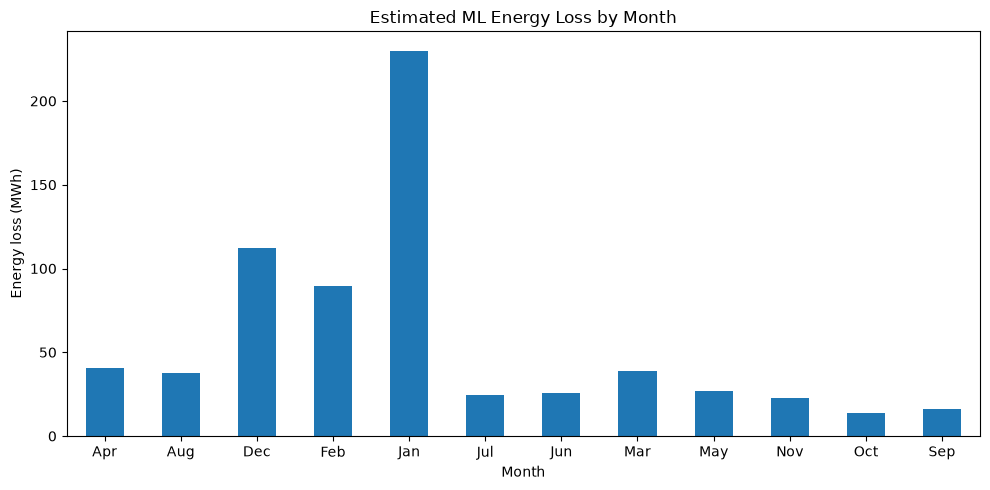

In [18]:
import matplotlib.pyplot as plt

monthly_loss = (
    features
    .groupby("month_name")["ml_shortfall_mwh"]
    .sum()
)

monthly_loss.plot(kind="bar", figsize=(10, 5))

plt.title("Estimated ML Energy Loss by Month")
plt.xlabel("Month")
plt.xticks(rotation=0)
plt.ylabel("Energy loss (MWh)")
plt.tight_layout()
plt.show()

# Handover Notes

## Completed work

This notebook completed the regression and loss-estimation stage of the project.

### Clustering decision

DBSCAN was selected over K-Means because it achieved the higher silhouette score (`0.615` versus `0.525`). DBSCAN identified cluster `0` as normal operation. However, the result was highly imbalanced: most operating-region records were assigned to cluster `0`, while the other clusters were very small. These should be described as suspected operating states, not confirmed faults.

### Regression decision

Random Forest and XGBoost were trained using normal-operation records only. XGBoost was selected because it achieved the best validation results:

- MAE: `202.33 kW`
- RMSE: `388.66 kW`
- R?: `0.882`

### Final results

- ML-estimated energy loss: `677.92 MWh`
- ML-estimated CO? impact: `501.66 tonnes`
- Manufacturer-baseline loss: `1,599.99 MWh`

## Files produced

- `out/03_regression/model_results.csv`
- `out/03_regression/regression_comparison.csv`
- `out/03_regression/loss_summary.csv`

## Next steps

1. Add the important tables and figures to the final report.
2. Explain that clusters are inferred states, not confirmed faults.
3. Mention that approximately `3.9%` of expected 10-minute intervals are missing and were not imputed.
4. Check the final numbers and rounding.
5. Combine this modelling section with the preprocessing and sustainability sections.
6. Consider adding a Pareto chart showing the largest loss categories.